## logistic regression


# preceptron trick and sigmoid function


In [69]:
import pandas as pd
from sklearn.datasets import make_classification

In [70]:
import numpy as np

In [71]:
X,y=make_classification(n_samples=100,n_features=2,n_redundant=0,n_informative=1,n_classes=2,n_clusters_per_class=1,random_state=41,hypercube=False,class_sep=10)

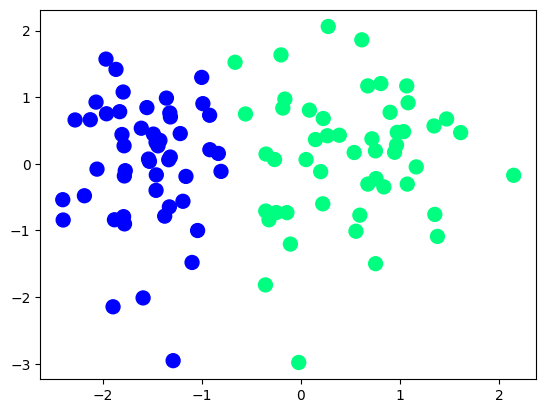

In [72]:
import matplotlib.pyplot as plt 
plt.scatter(X[:,0],X[:,1],c=y,s=100,cmap="winter")

In [73]:
# preceptron trick 
def Preceptron(X,y):
    X =np.insert(X,0,1,axis=1)
    Weight =np.ones(X.shape[1])
    lr=0.1
    for i in range(1000):
        j=np.random.randint(0,100)
        y_hat = step(np.dot(X[j],Weight))
        Weight = Weight +(lr*(y[j]-y_hat)*X[j])   
    return Weight[0] ,Weight[1:]    

In [74]:
def step(z):
    return 1 if z>0 else 0

In [75]:
# calling preceptron 
intercept,coefficient= Preceptron(X,y)

In [76]:
print(intercept)

1.0


In [77]:
print(coefficient)

[1.32060345 0.23072754]


## sigmoid function 

In [78]:
def sigmoid(X,y):
    X=np.insert(X,0,1,axis=1)
    Weight=np.ones(X.shape[1])
    lr=0.1

    for i in range(1000):
        j=np.random.randint(1,100)
        y_hat = sigm(np.dot(X[j],Weight))
        Weight =Weight + lr*(y[j]-y_hat)*X[j]
    return Weight[0] ,Weight[1:]    

In [79]:
def sigm(z):
    return 1/(np.exp(-z))

In [80]:
inn,coeffi=sigmoid(X,y)

In [81]:
print(inn)
print(coeffi)

-0.8694109170035443
[0.78280131 0.12128265]


## logistic regression 

In [82]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X,y)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [83]:
lr.intercept_

array([2.25106636])

In [84]:
lr.coef_

array([[3.50144121, 0.02773483]])